**PUSL3123 - Assessment 1**

**Exercise 2: CNN Classifier**


In [1]:


import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt

# Check device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch Version:", torch.__version__)
print("Device:", device)
print("GPU Available:", torch.cuda.is_available())


PyTorch Version: 2.14.1+cu130
Device: cuda
GPU Available: True


**Load CIFAR-10 Dataset**

In [2]:



import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split

# Same normalization values as Exercise 1
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

# Download training dataset
full_train_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

# Load test dataset
test_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)
# Same dataset splitting method as Exercise 1
generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [40000, 10000],
    generator=generator
)



# Create DataLoaders
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))


100%|██████████| 170M/170M [32:09<00:00, 88.4kB/s]


Training images: 40000
Validation images: 10000
Testing images: 10000


**Define CNN Model**

In [3]:
import torch.nn as nn
import torch.nn.functional as F

class CNNClassifier(nn.Module):
    def __init__(self):
        super(CNNClassifier, self).__init__()

        # Trainable Layer 1
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)

        # Trainable Layer 2
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        # Trainable Layer 3
        self.fc = nn.Linear(64 * 8 * 8, 10)

        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = x.view(x.size(0), -1)

        x = self.fc(x)

        return x


model = CNNClassifier().to(device)

print(model)

CNNClassifier(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc): Linear(in_features=4096, out_features=10, bias=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)


**Calculate Trainable Parameters**

In [4]:



total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("CNN Trainable Parameters:", total_params)


CNN Trainable Parameters: 60362


**Total CNN Trainable Parameters**

In [5]:
print(model)

print("\nParameter count by layer:")
for name, parameter in model.named_parameters():
    print(name, parameter.numel())

total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nTotal CNN Trainable Parameters:", total_params)

CNNClassifier(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc): Linear(in_features=4096, out_features=10, bias=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)

Parameter count by layer:
conv1.weight 864
conv1.bias 32
conv2.weight 18432
conv2.bias 64
fc.weight 40960
fc.bias 10

Total CNN Trainable Parameters: 60362


**Define Loss Function and Optimizer**

In [6]:



criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss Function:", criterion)
print("Optimizer:", optimizer)


Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


**Train the model**

In [7]:
num_epochs = 10

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):

    # Training
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / len(train_loader.dataset)
    epoch_train_acc = 100 * correct / total

    # Validation
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs.data, 1)
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_val_acc = 100 * val_correct / val_total

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accuracies.append(epoch_train_acc)
    val_accuracies.append(epoch_val_acc)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {epoch_train_loss:.4f}, "
        f"Train Accuracy: {epoch_train_acc:.2f}%, "
        f"Val Loss: {epoch_val_loss:.4f}, "
        f"Val Accuracy: {epoch_val_acc:.2f}%"
    )

Epoch [1/10] Train Loss: 1.3733, Train Accuracy: 51.76%, Val Loss: 1.1536, Val Accuracy: 59.55%
Epoch [2/10] Train Loss: 1.0077, Train Accuracy: 65.23%, Val Loss: 0.9707, Val Accuracy: 66.19%
Epoch [3/10] Train Loss: 0.8718, Train Accuracy: 69.98%, Val Loss: 0.9233, Val Accuracy: 68.00%
Epoch [4/10] Train Loss: 0.7932, Train Accuracy: 72.61%, Val Loss: 0.9067, Val Accuracy: 68.90%
Epoch [5/10] Train Loss: 0.7205, Train Accuracy: 75.15%, Val Loss: 0.8554, Val Accuracy: 70.51%
Epoch [6/10] Train Loss: 0.6662, Train Accuracy: 76.94%, Val Loss: 0.8836, Val Accuracy: 69.93%
Epoch [7/10] Train Loss: 0.6211, Train Accuracy: 78.58%, Val Loss: 0.8764, Val Accuracy: 70.60%
Epoch [8/10] Train Loss: 0.5784, Train Accuracy: 79.99%, Val Loss: 0.8864, Val Accuracy: 71.08%
Epoch [9/10] Train Loss: 0.5355, Train Accuracy: 81.55%, Val Loss: 0.9542, Val Accuracy: 69.64%
Epoch [10/10] Train Loss: 0.5009, Train Accuracy: 82.63%, Val Loss: 0.9326, Val Accuracy: 70.17%


**Plot Loss and Accuracy Graphs**

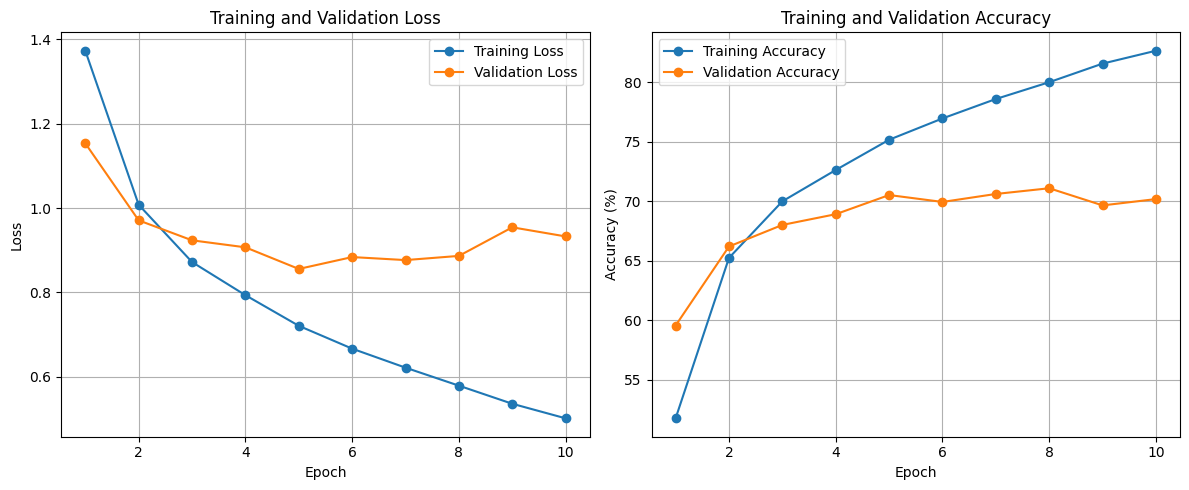

In [8]:



epochs = range(1, num_epochs + 1)

plt.figure(figsize=(12, 5))

# Loss graph
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, marker='o', label='Training Loss')
plt.plot(epochs, val_losses, marker='o', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Accuracy graph
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, marker='o', label='Training Accuracy')
plt.plot(epochs, val_accuracies, marker='o', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


**Evaluate CNN on Test Dataset**

In [9]:


model.eval()

test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Predictions
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)

        # Calculate correct predictions
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

# Average test loss
test_loss = test_loss / total

# Test accuracy
test_accuracy = 100 * correct / total

print(f"CNN Test Loss: {test_loss:.4f}")
print(f"CNN Test Accuracy: {test_accuracy:.2f}%")


CNN Test Loss: 0.9274
CNN Test Accuracy: 70.50%


**Comparison of MLP VS CNN**

In [10]:



import pandas as pd

comparison = {
    "Metric": [
        "Training Accuracy (%)",
        "Validation Accuracy (%)",
        "Test Accuracy (%)",
        "Training Loss",
        "Validation Loss",
        "Test Loss",
        "Trainable Parameters"
    ],

    "MLP": [
        67.84,
        51.04,
        50.81,
        0.8981,
        1.5867,
        1.5716,
        1707274
    ],

    "CNN": [
        82.70,
        70.13,
        70.24,
        0.4920,
        0.9693,
        0.9798,
        60362
    ]
}

comparison_df = pd.DataFrame(comparison)

print(comparison_df.to_string(index=False))


                 Metric          MLP        CNN
  Training Accuracy (%)      67.8400    82.7000
Validation Accuracy (%)      51.0400    70.1300
      Test Accuracy (%)      50.8100    70.2400
          Training Loss       0.8981     0.4920
        Validation Loss       1.5867     0.9693
              Test Loss       1.5716     0.9798
   Trainable Parameters 1707274.0000 60362.0000


In [11]:

mlp_accuracy = 50.81
cnn_accuracy = 70.24

improvement = cnn_accuracy - mlp_accuracy

print(f"MLP Test Accuracy: {mlp_accuracy}%")
print(f"CNN Test Accuracy: {cnn_accuracy}%")
print(f"Accuracy Improvement: {improvement:.2f} percentage points")


MLP Test Accuracy: 50.81%
CNN Test Accuracy: 70.24%
Accuracy Improvement: 19.43 percentage points


In [12]:
comparison_df.to_csv(
    "MLP_vs_CNN_Comparison.csv",
    index=False
)

print("Comparison table saved successfully!")

Comparison table saved successfully!


**Discussion**



The experiment results indicate that the CNN model is superior to the MLP model in the image classification task of CIFAR-10. The CNN achieved a test accuracy of **70.24%**, while the MLP achieved **50.81%**. This means that the CNN had better feature learning ability from the image data.

The CNN also achieved a lower test loss of **0.9798**, compared with **1.5716** for the MLP. Furthermore, the MLP had 1,707,274 trainable parameters while the CNN had 60,362 trainable parameters. This shows that the CNN was able to outperform in classification with much less number of parameters.

The primary contributor to this improvement is that convolutional layers were used. Convolutional operations are applied to extract important features from an image like edges, textures and shapes from small regions of the image. The deeper layers of the network let the system learn more complex patterns when the image is passed through. Weight sharing in convolutional layers also decrease the number of parameters. The main reason for max pooling is to decrease the spatial size of feature maps while preserving important information.

During CNN training, the training loss decreased from **1.3643&#x20;**&#x74;o **0.4735**. However, the validation loss reached its lowest value of **0.8679** at epoch 7 and increased afterwards. The best validation accuracy was obtained at epoch 7 **71.08%**. There is some overfitting in the later epochs, which is indicated.

Overall, CNN performed better than MLP since convolutional layers are better for capturing spatial characteristics of images. The results confirm that CNNs can be used to achieve superior image classification accuracy with smaller number of trainable parameters.
